# OLAP on supermarket sales: a star schema data warehouse in PostgreSQL

This notebook follows the *Practical Activity on OLAP* in the CSA 806 Module 5 notes. It builds a small data warehouse for a supermarket chain, loads it with an ETL process and then runs the four OLAP operations: **slice and dice, drill-down, roll-up and pivot**.

**Data.** The [Supermarket Sales](https://www.kaggle.com/datasets/shandeep777/supermarket-dataset) data on Kaggle. It holds 1,000 sales from three branches of a supermarket chain in Myanmar (Yangon, Mandalay and Naypyitaw) from January to March 2019. The data was first shared on Kaggle by Aung Pyae. This copy keeps the original branch codes (A, B and C) and the 24-hour times. It is not Kenyan data. It is used because it has every column the activity asks for (date, store location, product category, quantity, price and payment method) plus the time of each sale.

**Database.** PostgreSQL 17. The `docker-compose.yml` next to this notebook starts one on port 5433. The connection can be changed with the usual `PGHOST`, `PGPORT`, `PGUSER`, `PGPASSWORD` and `PGDATABASE` variables.

## 1. Setup
The libraries are loaded and the folders for data and figures are made.

In [1]:
import os, json, shutil, logging, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
logging.getLogger('kagglehub').setLevel(logging.WARNING)       # hide the local cache path
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import kagglehub, psycopg
from psycopg.types.numeric import FloatLoader
DATA, FIG, SQL = Path('data'), Path('figures'), Path('sql')
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
# Okabe-Ito colours, a colour-blind safe set, always used in the same order
COLS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e6', 'grid.linewidth': 0.6})
print('pandas', pd.__version__, '| psycopg', psycopg.__version__, '| kagglehub', kagglehub.__version__)

pandas 3.1.1 | psycopg 3.3.9 | kagglehub 1.0.3


## 2. Download the data from Kaggle
`kagglehub` downloads public Kaggle data sets without an account. The file (about 130 KB) is copied into `data/`.

In [2]:
src = Path(kagglehub.dataset_download('shandeep777/supermarket-dataset')) / 'supermarket_sales - Sheet1.csv'
CSV = DATA / 'supermarket_sales.csv'
shutil.copy(src, CSV)
raw = pd.read_csv(CSV)
print(raw.shape)
raw.head()

(1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## 3. Explore the data and check its quality
Before loading, the file is checked for gaps, repeated invoices and sums that do not add up. In this data the pre-tax amount is called `cogs` and equals unit price times quantity. `Total` adds a 5% tax.

In [3]:
raw['Date'] = pd.to_datetime(raw['Date'], format='%m/%d/%Y')
raw['Hour'] = raw['Time'].str.split(':').str[0].astype(int)
checks = {
    'rows': len(raw),
    'missing_values': int(raw.isna().sum().sum()),
    'repeated_rows': int(raw.duplicated().sum()),
    'repeated_invoices': int(raw['Invoice ID'].duplicated().sum()),
    'cogs_equals_price_x_qty': bool(np.allclose(raw['cogs'], raw['Unit price'] * raw['Quantity'])),
    'total_equals_cogs_plus_tax': bool(np.allclose(raw['Total'], raw['cogs'] * 1.05)),
    'first_date': str(raw['Date'].min().date()), 'last_date': str(raw['Date'].max().date()),
    'days': int(raw['Date'].nunique()),
    'first_hour': int(raw['Hour'].min()), 'last_hour': int(raw['Hour'].max()),
}
for k, v in checks.items():
    print(f'{k:28s} {v}')
for col in ['Branch', 'City', 'Product line', 'Payment', 'Customer type']:
    print(col, raw[col].value_counts().to_dict())

rows                         1000
missing_values               0
repeated_rows                0
repeated_invoices            0
cogs_equals_price_x_qty      True
total_equals_cogs_plus_tax   True
first_date                   2019-01-01
last_date                    2019-03-30
days                         89
first_hour                   10
last_hour                    20
Branch {'A': 340, 'B': 332, 'C': 328}
City {'Yangon': 340, 'Mandalay': 332, 'Naypyitaw': 328}
Product line {'Fashion accessories': 178, 'Food and beverages': 174, 'Electronic accessories': 170, 'Sports and travel': 166, 'Home and lifestyle': 160, 'Health and beauty': 152}
Payment {'Ewallet': 345, 'Cash': 344, 'Credit card': 311}
Customer type {'Member': 501, 'Normal': 499}


## 4. Build the star schema
A separate database `supermarket_dw` is made if it does not exist yet. `sql/01_schema.sql` then creates the staging table, five dimension tables and the fact table.

- **Fact table** `fact_sales`: one row per sale with the keys of each dimension and the measures quantity, unit price, total sales (price times quantity) and tax.
- **Dimensions** `dim_date` (day, month, quarter, year, weekday), `dim_time` (hour and part of the day), `dim_store` (branch, city, region), `dim_product` (category) and `dim_payment` (payment method).

`dim_time` is an addition to the schema in the notes. Without it sales could not be drilled down to the hour.

In [4]:
PG = dict(host=os.getenv('PGHOST', 'localhost'), port=int(os.getenv('PGPORT', '5433')),
          user=os.getenv('PGUSER', 'dw'), password=os.getenv('PGPASSWORD', 'dw_local_test'))
DB = os.getenv('PGDATABASE', 'supermarket_dw')
with psycopg.connect(dbname='postgres', autocommit=True, **PG) as admin:
    if not admin.execute('SELECT 1 FROM pg_database WHERE datname = %s', (DB,)).fetchone():
        admin.execute(f'CREATE DATABASE {DB}')
conn = psycopg.connect(dbname=DB, autocommit=True, **PG)
conn.adapters.register_loader('numeric', FloatLoader)          # NUMERIC values come back as floats
conn.execute((SQL / '01_schema.sql').read_text())
print(conn.execute('SELECT version()').fetchone()[0].split(' on ')[0])
print([r[0] for r in conn.execute("SELECT table_name FROM information_schema.tables WHERE table_schema = 'public' ORDER BY 1")])

PostgreSQL 17.12 (Debian 17.12-1.pgdg13+1)
['dim_date', 'dim_payment', 'dim_product', 'dim_store', 'dim_time', 'fact_sales', 'stg_sales']


## 5. Extract
The CSV is copied unchanged into the staging table with PostgreSQL's fast `COPY` command.

In [5]:
with conn.cursor() as cur, cur.copy('COPY stg_sales FROM STDIN WITH (FORMAT csv, HEADER true)') as cp:
    cp.write(CSV.read_bytes())
print('staging rows', conn.execute('SELECT count(*) FROM stg_sales').fetchone()[0])

staging rows 1000


## 6. Transform and load
`sql/02_etl.sql` trims spaces and drops repeated invoices, splits each date into its parts, fills the dimension tables first and then fills the fact table by looking up each key. It also creates the view `v_sales`, which joins the fact table to all its dimensions. The checks below confirm that nothing was lost: the row count and the sales total in the warehouse must match the CSV.

In [6]:
conn.execute((SQL / '02_etl.sql').read_text())

def q(sql):
    """Run a query and return the result as a DataFrame."""
    with conn.cursor() as cur:
        cur.execute(sql)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])

counts = q("""SELECT 'dim_date' AS table_name, count(*) AS rows FROM dim_date UNION ALL
            SELECT 'dim_time', count(*) FROM dim_time UNION ALL SELECT 'dim_store', count(*) FROM dim_store UNION ALL
            SELECT 'dim_product', count(*) FROM dim_product UNION ALL SELECT 'dim_payment', count(*) FROM dim_payment UNION ALL
            SELECT 'fact_sales', count(*) FROM fact_sales""")
print(counts.to_string(index=False))
dw = q('SELECT sum(total_sales) AS sales, sum(total_sales + tax_amount) AS with_tax, sum(quantity) AS units FROM fact_sales').iloc[0]
recon = {'warehouse_sales': round(dw['sales'], 2), 'csv_cogs': round(raw['cogs'].sum(), 2),
         'warehouse_with_tax': round(dw['with_tax'], 2), 'csv_total': round(raw['Total'].sum(), 2),
         'warehouse_units': int(dw['units']), 'csv_units': int(raw['Quantity'].sum())}
print(recon)
assert counts.set_index('table_name').loc['fact_sales', 'rows'] == len(raw)
assert abs(recon['warehouse_sales'] - recon['csv_cogs']) < 0.01 and recon['warehouse_units'] == recon['csv_units']
print(q('SELECT * FROM dim_store').to_string(index=False))

 table_name  rows
   dim_date    89
   dim_time    24
  dim_store     3
dim_product     6
dim_payment     3
 fact_sales  1000
{'warehouse_sales': np.float64(307587.38), 'csv_cogs': np.float64(307587.38), 'warehouse_with_tax': np.float64(322966.75), 'csv_total': np.float64(322966.75), 'warehouse_units': 5510, 'csv_units': 5510}
 store_id branch_code store_location                    region
        1           A         Yangon             Yangon Region
        2           B       Mandalay           Mandalay Region
        3           C      Naypyitaw Naypyidaw Union Territory


## 7. OLAP operations
The queries are kept in `sql/03_olap_queries.sql`. Each one starts with a `-- name:` line so it can be run here by name. All sales figures are before the 5% tax.

In [7]:
QUERIES = {}
for block in (SQL / '03_olap_queries.sql').read_text().split('-- name: ')[1:]:
    name, body = block.split('\n', 1)
    QUERIES[name.strip()] = body
R = {name: q(sql) for name, sql in QUERIES.items()}
print(list(R))

['slice_yangon', 'slice_city_category', 'dice', 'drill_month', 'drill_day', 'drill_hour', 'weekday', 'rollup', 'rollup_week', 'pivot_store_month', 'pivot_category_month', 'cube', 'payment_store']


### 7.1 Slice
A slice fixes one dimension to a single value. Here the store is fixed to **Yangon** and each category's share of sales there is set beside its share across all three stores.

In [8]:
sl = R['slice_yangon'].assign(diff_pts=lambda d: d['yangon_share_pct'] - d['all_share_pct'])
print(sl.to_string(index=False))
sc = R['slice_city_category']
top = sc.loc[sc.groupby('store_location')['sales'].idxmax()]
print('\nBest category in each store')
print(top.to_string(index=False))

              category  yangon_sales  yangon_share_pct  all_sales  all_share_pct  diff_pts
    Home and lifestyle      21349.71              21.1   51297.06           16.7       4.4
     Sports and travel      18450.19              18.2   52497.93           17.1       1.1
Electronic accessories      17444.87              17.2   51750.03           16.8       0.4
    Food and beverages      16345.81              16.2   53471.28           17.4      -1.2
   Fashion accessories      15554.77              15.4   51719.90           16.8      -1.4
     Health and beauty      11997.86              11.9   46851.18           15.2      -3.3

Best category in each store
store_location           category    sales  units
      Mandalay  Sports and travel 19036.38    322
     Naypyitaw Food and beverages 22635.10    369
        Yangon Home and lifestyle 21349.71    371


### 7.2 Dice
A dice cuts a smaller cube on several dimensions at once. Here it keeps two stores (Mandalay and Naypyitaw), two categories (food and beverages, health and beauty) and only e-wallet payments, split by month.

In [9]:
dc = R['dice']
print(dc.to_string(index=False))
print('\ninvoices in the dice', int(dc['invoices'].sum()), 'of', len(raw), '| sales', round(dc['sales'].sum(), 2))

store_location           category month_name  invoices   sales
      Mandalay Food and beverages    January         4  896.24
      Mandalay Food and beverages   February         8 1784.43
      Mandalay Food and beverages      March         5 1113.76
      Mandalay  Health and beauty    January         3  834.88
      Mandalay  Health and beauty   February         6 1418.95
      Mandalay  Health and beauty      March        10 3512.62
     Naypyitaw Food and beverages    January         6 2384.58
     Naypyitaw Food and beverages   February         4 1043.02
     Naypyitaw Food and beverages      March        10 3204.15
     Naypyitaw  Health and beauty    January         9 2256.93
     Naypyitaw  Health and beauty   February         7 1411.07
     Naypyitaw  Health and beauty      March         2  927.16

invoices in the dice 74 of 1000 | sales 20787.79


### 7.3 Drill-down
Drill-down moves from a summary to more detail: from months to days to hours.

In [10]:
dm = R['drill_month']
print(dm.pivot(index='store_location', columns='month_name', values='sales')[['January', 'February', 'March']].round(2))
dd = R['drill_day']
daily_all = dd.groupby('date_value', as_index=False)['sales'].sum()
best_month = int(dm.groupby('month')['sales'].sum().idxmax())
print('\nbest month overall', best_month)
print('busiest days overall')
print(daily_all.nlargest(5, 'sales').to_string(index=False))
dh = R['drill_hour']
peak = dh.loc[dh.groupby('store_location')['sales'].idxmax()]
print('\npeak hour in each store')
print(peak.to_string(index=False))
hour_all = dh.groupby('hour', as_index=False)[['invoices', 'sales']].sum()
print('\nall stores by hour')
print(hour_all.to_string(index=False))
wd = R['weekday']
wd_all = wd.groupby(['dow', 'day_of_week'], as_index=False)['sales'].sum()
print('\nall stores by weekday')
print(wd_all.to_string(index=False))
print('\nbusiest weekday in each store')
print(wd.loc[wd.groupby('store_location')['sales'].idxmax()].to_string(index=False))

month_name       January  February     March
store_location                              
Mandalay        35405.77  32785.02  32949.85
Naypyitaw       38509.22  31366.65  35427.66
Yangon          36839.17  28438.21  35865.83

best month overall 1
busiest days overall
date_value   sales
2019-03-09 7118.14
2019-02-07 6884.01
2019-03-14 6871.08
2019-02-15 6505.51
2019-03-02 6247.91

peak hour in each store
store_location  hour  invoices    sales
      Mandalay    19        50 15488.05
     Naypyitaw    19        36 12482.67
        Yangon    11        35 10809.42

all stores by hour
 hour  invoices    sales
   10       101 29925.22
   11        90 28930.79
   12        89 24824.65
   13       103 33069.74
   14        83 29360.38
   15       102 29694.77
   16        77 24025.07
   17        74 23281.16
   18        93 24790.80
   19       113 37809.06
   20        75 21875.74

all stores by weekday
 dow day_of_week    sales
   1      Monday 36094.36
   2     Tuesday 49030.71
   3   Wedne

### 7.4 Roll-up
Roll-up goes the other way. `GROUP BY ROLLUP` sums the sales to months, then to the quarter, then to a grand total in a single query. Rows with an empty month are subtotals. The data covers one quarter only, so quarter-over-quarter growth cannot be measured. Month-over-month change and the weekly totals are used instead.

In [11]:
ru = R['rollup']
print(ru.to_string(index=False))
months = ru.dropna(subset=['month']).reset_index(drop=True)
months['change_pct'] = (months['sales'].pct_change() * 100).round(1)
print(months[['month', 'sales', 'change_pct']].to_string(index=False))
rw = R['rollup_week']
print(rw.to_string(index=False))

  year  quarter  month     sales  invoices
2019.0      1.0    1.0 110754.16       352
2019.0      1.0    2.0  92589.88       303
2019.0      1.0    3.0 104243.34       345
2019.0      1.0    NaN 307587.38      1000
2019.0      NaN    NaN 307587.38      1000
   NaN      NaN    NaN 307587.38      1000
 month     sales  change_pct
   1.0 110754.16         NaN
   2.0  92589.88       -16.4
   3.0 104243.34        12.6
 week_of_year  first_day   last_day  days    sales
            1 2019-01-01 2019-01-06     6 16707.99
            2 2019-01-07 2019-01-13     7 23296.38
            3 2019-01-14 2019-01-20     7 27327.01
            4 2019-01-21 2019-01-27     7 27892.27
            5 2019-01-28 2019-02-03     7 27009.95
            6 2019-02-04 2019-02-10     7 25811.27
            7 2019-02-11 2019-02-17     7 24346.28
            8 2019-02-18 2019-02-24     7 16503.49
            9 2019-02-25 2019-03-03     7 27828.30
           10 2019-03-04 2019-03-10     7 27065.56
           11 2019-03-

### 7.5 Pivot
Pivot turns the view. The first view puts stores in rows and months in columns. The second turns the same measure so that product categories are the rows.

In [12]:
ps, pc = R['pivot_store_month'], R['pivot_category_month']
print(ps.to_string(index=False)); print(); print(pc.to_string(index=False))
best_cat_month = {m: pc.loc[pc[m].idxmax(), 'category'] for m in ['january', 'february', 'march']}
print('\nbest category each month', best_cat_month)

store_location  january  february    march     total
      Mandalay 35405.77  32785.02 32949.85 101140.64
     Naypyitaw 38509.22  31366.65 35427.66 105303.53
        Yangon 36839.17  28438.21 35865.83 101143.21

              category  january  february    march    total
    Food and beverages 18638.60  19047.96 15784.72 53471.28
     Sports and travel 20635.26  13152.01 18710.66 52497.93
Electronic accessories 17934.56  16536.10 17279.37 51750.03
   Fashion accessories 18423.92  18104.63 15191.35 51719.90
    Home and lifestyle 19518.80  11842.27 19935.99 51297.06
     Health and beauty 15603.02  13906.91 17341.25 46851.18

best category each month {'january': 'Sports and travel', 'february': 'Food and beverages', 'march': 'Home and lifestyle'}


### 7.6 The full cube
`GROUP BY CUBE` gives every combination of store and category plus all subtotals and the grand total. Level 0 rows are single cells, levels 1 and 2 are subtotals and level 3 is the grand total. The payment mix in each store is also shown.

In [13]:
cb = R['cube']
print(cb.groupby('level').size().to_dict())
print(cb[cb['level'] > 0].to_string(index=False))
pay = R['payment_store']
print(pay.pivot(index='store_location', columns='payment_method', values='invoices'))

{0: 18, 1: 3, 2: 6, 3: 1}
store_location               category     sales  level
      Mandalay         All categories 101140.64      1
     Naypyitaw         All categories 105303.53      1
        Yangon         All categories 101143.21      1
    All stores Electronic accessories  51750.03      2
    All stores    Fashion accessories  51719.90      2
    All stores     Food and beverages  53471.28      2
    All stores      Health and beauty  46851.18      2
    All stores     Home and lifestyle  51297.06      2
    All stores      Sports and travel  52497.93      2
    All stores         All categories 307587.38      3
payment_method  Cash  Credit card  Ewallet
store_location                            
Mandalay         110          109      113
Naypyitaw        124           98      106
Yangon           110          104      126


## 8. The same views as spreadsheet pivot tables
The notes also allow a simpler approach with spreadsheet pivot tables. `pandas.pivot_table` works the same way: dimensions go to rows and columns and the measure is summed. The results must match the SQL views exactly.

In [14]:
flat = q('SELECT * FROM v_sales')
pt_store = flat.pivot_table(index='store_location', columns='month', values='total_sales', aggfunc='sum', margins=True, margins_name='Total').round(2)
pt_cat = flat.pivot_table(index='category', columns='month', values='total_sales', aggfunc='sum').round(2)
print(pt_store)
match_store = np.allclose(pt_store.loc[ps['store_location'], [1, 2, 3]].values, ps[['january', 'february', 'march']].values)
match_cat = np.allclose(pt_cat.loc[pc['category'], [1, 2, 3]].values, pc[['january', 'february', 'march']].values)
print('pivot tables match SQL:', match_store, match_cat)

month                   1         2          3      Total
store_location                                           
Mandalay         35405.77  32785.02   32949.85  101140.64
Naypyitaw        38509.22  31366.65   35427.66  105303.53
Yangon           36839.17  28438.21   35865.83  101143.21
Total           110754.16  92589.88  104243.34  307587.38
pivot tables match SQL: True True


## 9. Figures

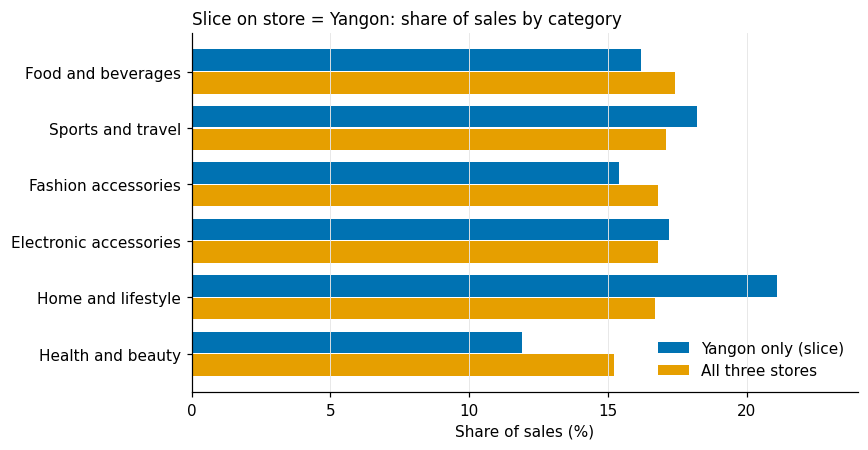

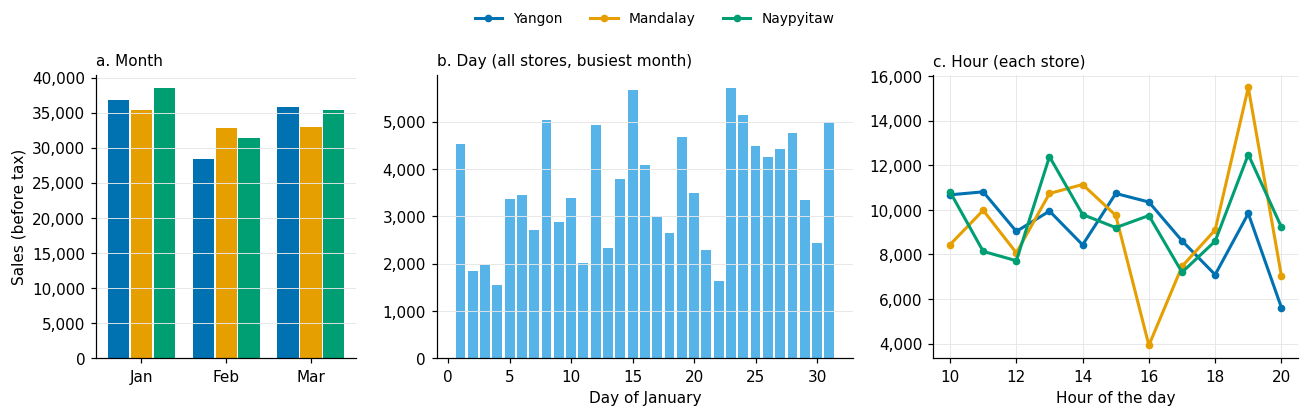

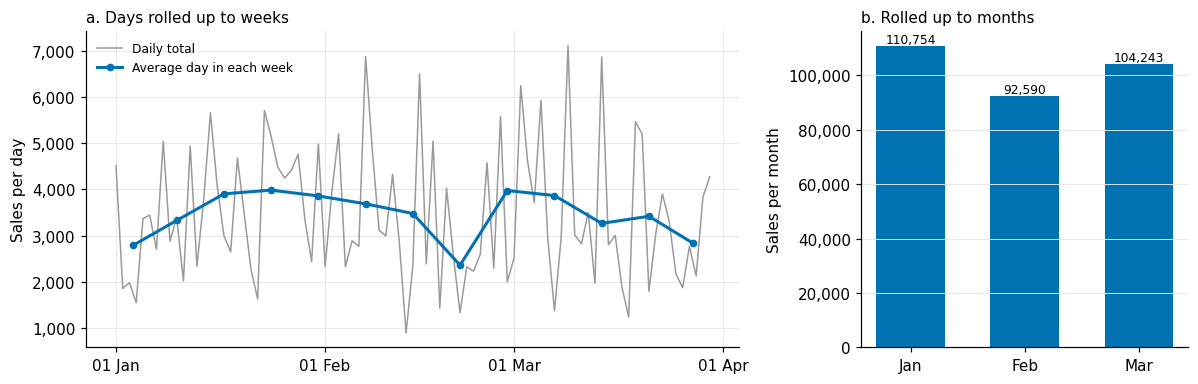

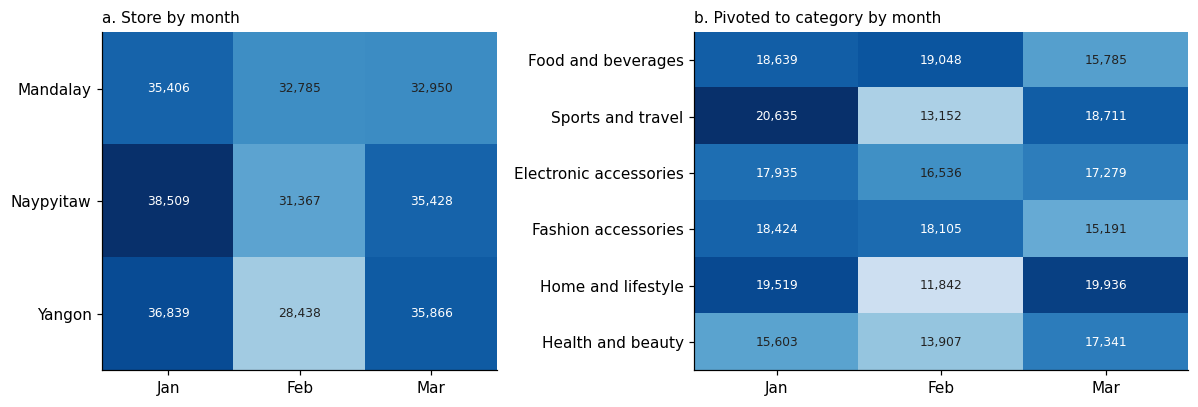

In [15]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
THOU = FuncFormatter(lambda v, _: f'{v:,.0f}')
stores = ['Yangon', 'Mandalay', 'Naypyitaw']
SC = dict(zip(stores, COLS[:3]))

# Figure 1. Slice: category shares in Yangon against all stores
fig, ax = plt.subplots(figsize=(8, 4.2))
s = sl.sort_values('all_share_pct')
y = np.arange(len(s))
ax.barh(y + 0.2, s['yangon_share_pct'], 0.38, color=COLS[0], label='Yangon only (slice)')
ax.barh(y - 0.2, s['all_share_pct'], 0.38, color=COLS[1], label='All three stores')
ax.set_yticks(y, s['category']); ax.set_xlabel('Share of sales (%)')
ax.grid(axis='y', visible=False); ax.legend(loc='lower right', frameon=False)
ax.set_title('Slice on store = Yangon: share of sales by category', loc='left', fontsize=11)
ax.set_xlim(0, 24)
fig.tight_layout(); fig.savefig(FIG / 'slice_yangon.png', dpi=200); plt.show()

# Figure 2. Drill-down: month, then day, then hour
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.6, 1.4]})
mm = dm.pivot(index='month', columns='store_location', values='sales')[stores]
x = np.arange(3)
for i, st in enumerate(stores):
    axes[0].bar(x + (i - 1) * 0.27, mm[st], 0.25, color=SC[st], label=st)
axes[0].set_xticks(x, ['Jan', 'Feb', 'Mar']); axes[0].set_ylabel('Sales (before tax)')
axes[0].set_title('a. Month', loc='left', fontsize=10); axes[0].grid(axis='x', visible=False)
dmo = daily_all[pd.to_datetime(daily_all['date_value']).dt.month == best_month]
axes[1].bar(pd.to_datetime(dmo['date_value']).dt.day, dmo['sales'], 0.8, color=COLS[4])
axes[1].set_xlabel('Day of ' + ['January', 'February', 'March'][best_month - 1])
axes[1].set_title('b. Day (all stores, busiest month)', loc='left', fontsize=10); axes[1].grid(axis='x', visible=False)
for st in stores:
    h = dh[dh.store_location == st]
    axes[2].plot(h['hour'], h['sales'], marker='o', ms=4, lw=2, color=SC[st], label=st)
axes[2].set_xlabel('Hour of the day'); axes[2].set_xticks(range(10, 21, 2))
axes[2].set_title('c. Hour (each store)', loc='left', fontsize=10)
for ax in axes: ax.yaxis.set_major_formatter(THOU)
fig.legend(*axes[2].get_legend_handles_labels(), loc='upper center', ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(FIG / 'drill_down.png', dpi=200); plt.show()

# Figure 3. Roll-up: daily totals summed to weeks and months
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [2, 1]})
dts = pd.to_datetime(daily_all['date_value'])
axes[0].plot(dts, daily_all['sales'], color='#9a9a9a', lw=1, label='Daily total')
wk = daily_all.assign(week=dts.dt.isocalendar().week.values).groupby('week')['sales'].mean()
wk_mid = daily_all.assign(week=dts.dt.isocalendar().week.values, d=dts).groupby('week')['d'].median()
axes[0].plot(wk_mid, wk, color=COLS[0], lw=2, marker='o', ms=4, label='Average day in each week')
axes[0].set_ylabel('Sales per day'); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title('a. Days rolled up to weeks', loc='left', fontsize=10)
axes[0].xaxis.set_major_locator(mdates.MonthLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
for ax in axes: ax.yaxis.set_major_formatter(THOU)
axes[1].bar(['Jan', 'Feb', 'Mar'], months['sales'], color=COLS[0], width=0.6)
for i, v in enumerate(months['sales']):
    axes[1].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=8)
axes[1].set_ylabel('Sales per month'); axes[1].grid(axis='x', visible=False)
axes[1].set_title('b. Rolled up to months', loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'roll_up.png', dpi=200); plt.show()

# Figure 4. Pivot: store by month turned into category by month
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.25]})
for ax, (tbl, idx, title) in zip(axes, [(ps, 'store_location', 'a. Store by month'), (pc, 'category', 'b. Pivoted to category by month')]):
    m = tbl.set_index(idx)[['january', 'february', 'march']]
    ax.imshow(m.values, cmap='Blues', aspect='auto', vmin=0.8 * m.values.min(), vmax=m.values.max())
    ax.set_xticks(range(3), ['Jan', 'Feb', 'Mar']); ax.set_yticks(range(len(m)), m.index)
    ax.grid(False); ax.set_title(title, loc='left', fontsize=10)
    hi = m.values.max()
    for i in range(m.shape[0]):
        for j in range(3):
            v = m.values[i, j]
            ax.text(j, i, f'{v:,.0f}', ha='center', va='center', fontsize=8,
                    color='white' if v > m.values.min() + 0.55 * (hi - m.values.min()) else '#222')
fig.tight_layout(); fig.savefig(FIG / 'pivot.png', dpi=200); plt.show()

## 10. Save the results
The numbers used in the report are written to `results_olap.json`.

In [16]:
recs = lambda d: json.loads(d.to_json(orient='records', date_format='iso'))
out = {
    'checks': checks, 'reconcile': recon, 'table_rows': dict(zip(counts.table_name, counts.rows.astype(int))),
    'slice_yangon': recs(sl), 'best_category_by_store': recs(top), 'slice_city_category': recs(sc),
    'dice': recs(dc), 'drill_month': recs(dm), 'busiest_days': recs(daily_all.nlargest(5, 'sales')),
    'quietest_days': recs(daily_all.nsmallest(5, 'sales')), 'best_month': best_month,
    'peak_hour_by_store': recs(peak), 'hour_all': recs(hour_all), 'weekday_all': recs(wd_all),
    'weekday_by_store': recs(wd), 'rollup': recs(ru), 'months': recs(months), 'rollup_week': recs(rw),
    'pivot_store_month': recs(ps), 'pivot_category_month': recs(pc), 'best_category_by_month': best_cat_month,
    'cube_subtotals': recs(cb[cb['level'] > 0]), 'payment_store': recs(pay),
    'pivot_tables_match_sql': bool(match_store and match_cat),
}
Path('results_olap.json').write_text(json.dumps(out, indent=1))
conn.close()
print('saved results_olap.json')

saved results_olap.json
